# ML Assignment 2 - Classification Models & Evaluation
**Dataset:** UCI Breast Cancer Wisconsin (Diagnostic) - 569 instances, 30 numeric features, binary target (malignant / benign).

Models: Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM (RBF). Metrics: Accuracy, AUC, Precision, Recall, F1, MCC.
Run this notebook from the project folder; it writes `test_data.csv` and `model/*.joblib` used by `app.py`.

In [1]:
import json, joblib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_curve
from metrics_utils import TARGET_COL, MODEL_FILES, CLASS_NAMES, score_model
import os; os.makedirs("model", exist_ok=True)
SEED = 42

## 1. Load data & basic EDA

In [2]:
raw = load_breast_cancer(as_frame=True)
X = raw.data
y = 1 - raw.target; y.name = TARGET_COL      # malignant = 1 (positive class)
print("Instances:", X.shape[0], "| Features:", X.shape[1])
print("Missing values:", int(X.isna().sum().sum()))
print(y.value_counts().rename({0:"benign",1:"malignant"}))
X.describe().T.head(10)

Instances: 569 | Features: 30
Missing values: 0
diagnosis
benign       357
malignant    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


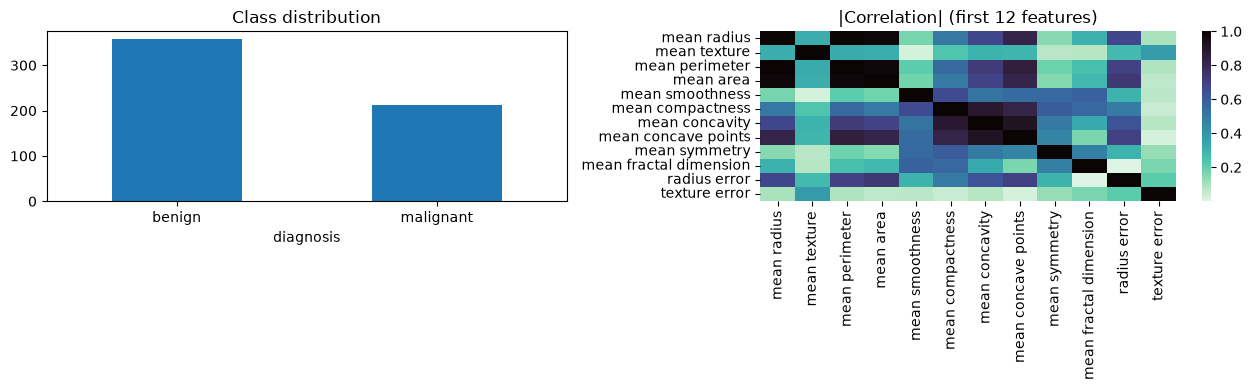

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
y.map({0:"benign",1:"malignant"}).value_counts().plot.bar(ax=axes[0], rot=0, title="Class distribution")
corr = X.corr().abs()
sns.heatmap(corr.iloc[:12,:12], cmap="mako_r", ax=axes[1]); axes[1].set_title("|Correlation| (first 12 features)")
plt.tight_layout(); plt.show()

## 2. Train / test split (80/20, stratified) and export `test_data.csv`

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
pd.concat([X_test, y_test], axis=1).to_csv("test_data.csv", index=False)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## 3. Train the five models
Scaling is part of each Pipeline so the fitted scaler is saved with the model.

In [5]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=3, random_state=SEED),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(kernel="rbf", C=1.0, random_state=SEED), ensemble=False)),
}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    joblib.dump(model, f"model/{MODEL_FILES[name]}")
    rows.append({"ML Model Name": name, **score_model(model, X_test, y_test)})
results = pd.DataFrame(rows).round(4)
results.to_csv("model/metrics.csv", index=False)
Path("model/feature_names.json").write_text(json.dumps(list(X.columns)))
results

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9035,0.9471,0.9429,0.7857,0.8571,0.7926
2,KNN,0.9561,0.9825,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,0.9756,0.9524,0.9639,0.9433


## 4. Confusion matrices & ROC curves

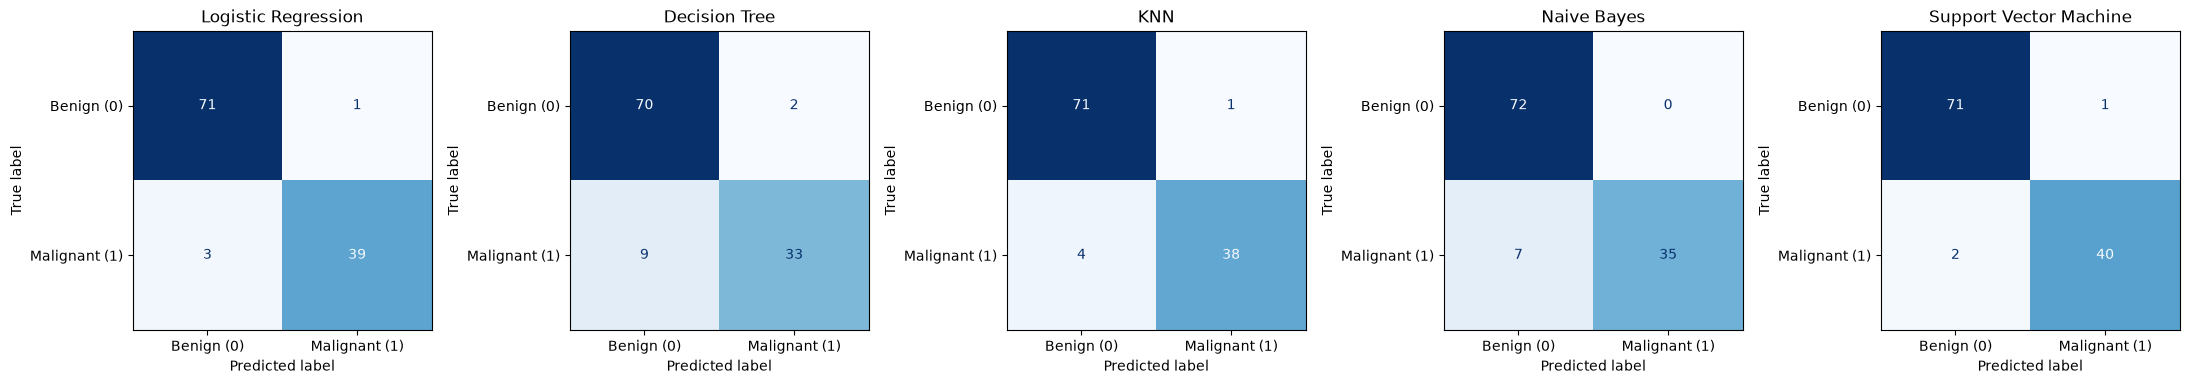

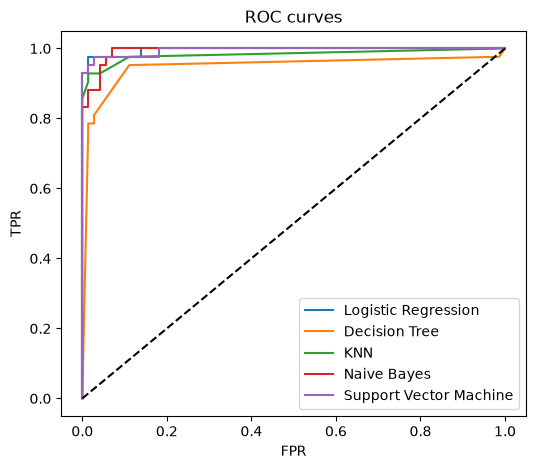

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), display_labels=CLASS_NAMES, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6,5))
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:,1]); plt.plot(fpr, tpr, label=name)
plt.plot([0,1],[0,1],"k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title("ROC curves"); plt.show()

In [7]:
for name, m in models.items():
    print("=== ", name); print(classification_report(y_test, m.predict(X_test), target_names=CLASS_NAMES))

===  Logistic Regression
               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114

===  Decision Tree
               precision    recall  f1-score   support

   Benign (0)       0.89      0.97      0.93        72
Malignant (1)       0.94      0.79      0.86        42

     accuracy                           0.90       114
    macro avg       0.91      0.88      0.89       114
 weighted avg       0.91      0.90      0.90       114

===  KNN
               precision    recall  f1-score   support

   Benign (0)       0.95      0.99      0.97        72
Malignant (1)       0.97      0.90      0.94        42

     accuracy                           0.96       114
    macro avg       0.96      0.95      0.95       114
 wei

## 5. Comparison & winner

In [8]:
ranked = results.set_index("ML Model Name").sort_values("MCC", ascending=False)
display(ranked.style.highlight_max(axis=0, color="#cfe8cf"))
print("Winner (by MCC):", ranked.index[0])

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Support Vector Machine,0.973700,0.994700,0.975600,0.952400,0.963900,0.943300
Logistic Regression,0.964900,0.996000,0.975000,0.928600,0.951200,0.924500
KNN,0.956100,0.982500,0.974400,0.904800,0.938300,0.905800
Naive Bayes,0.938600,0.993400,1.000000,0.833300,0.909100,0.871500
Decision Tree,0.903500,0.947100,0.942900,0.785700,0.857100,0.792600


Winner (by MCC): Support Vector Machine


## 6. Observations
See the observation table in `README.md` (written from the numbers produced above). Re-running the notebook with the fixed seed reproduces them.